# P43 (clean rerun): local_tol's decayed-tail losses

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-11-16_p43-clean-rerun"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


In [2]:
import importlib, sys
from IPython.display import Image, display
R = REPO / 'reports' / '2026-11-16_p43-clean-rerun'
sys.path.insert(0, str(R))
import analysis as A
importlib.reload(A)
summary = pd.read_csv(R / 'data' / 'summary_table.csv')
summary.round(3)

,dataset,variant,n,success,wrong,alias,none,precision,median_s
0,dmfy,_v7 (local_screen2),874,0.254,0.038,0.008,0.700,0.847,1.248
1,dmfy,local_tol_cs,874,0.255,0.019,0.008,0.717,0.903,1.010
2,dmfy,local_tol_cs_trim,874,0.268,0.026,0.010,0.696,0.880,1.043
3,dmfy,local_tol,874,0.252,0.019,0.008,0.721,0.902,0.856
4,dmfy,local_tol_trim,874,0.265,0.024,0.009,0.701,0.889,0.912
5,dmas,_v7 (local_screen2),874,0.146,0.029,0.005,0.820,0.815,0.841
6,dmas,local_tol_cs,874,0.144,0.025,0.006,0.825,0.824,0.388
7,dmas,local_tol_cs_trim,874,0.157,0.032,0.006,0.805,0.806,0.538
8,dmas,local_tol,874,0.143,0.024,0.005,0.828,0.833,0.460
9,dmas,local_tol_trim,874,0.153,0.030,0.006,0.811,0.812,0.457


## Headline table
Official scorecard metrics (`data/metrics/`) and the clean `_v7` baselines; precision = success / answered.

## Outcomes by period bin (harness screen, all stars; identical to the official scorecards where both exist)

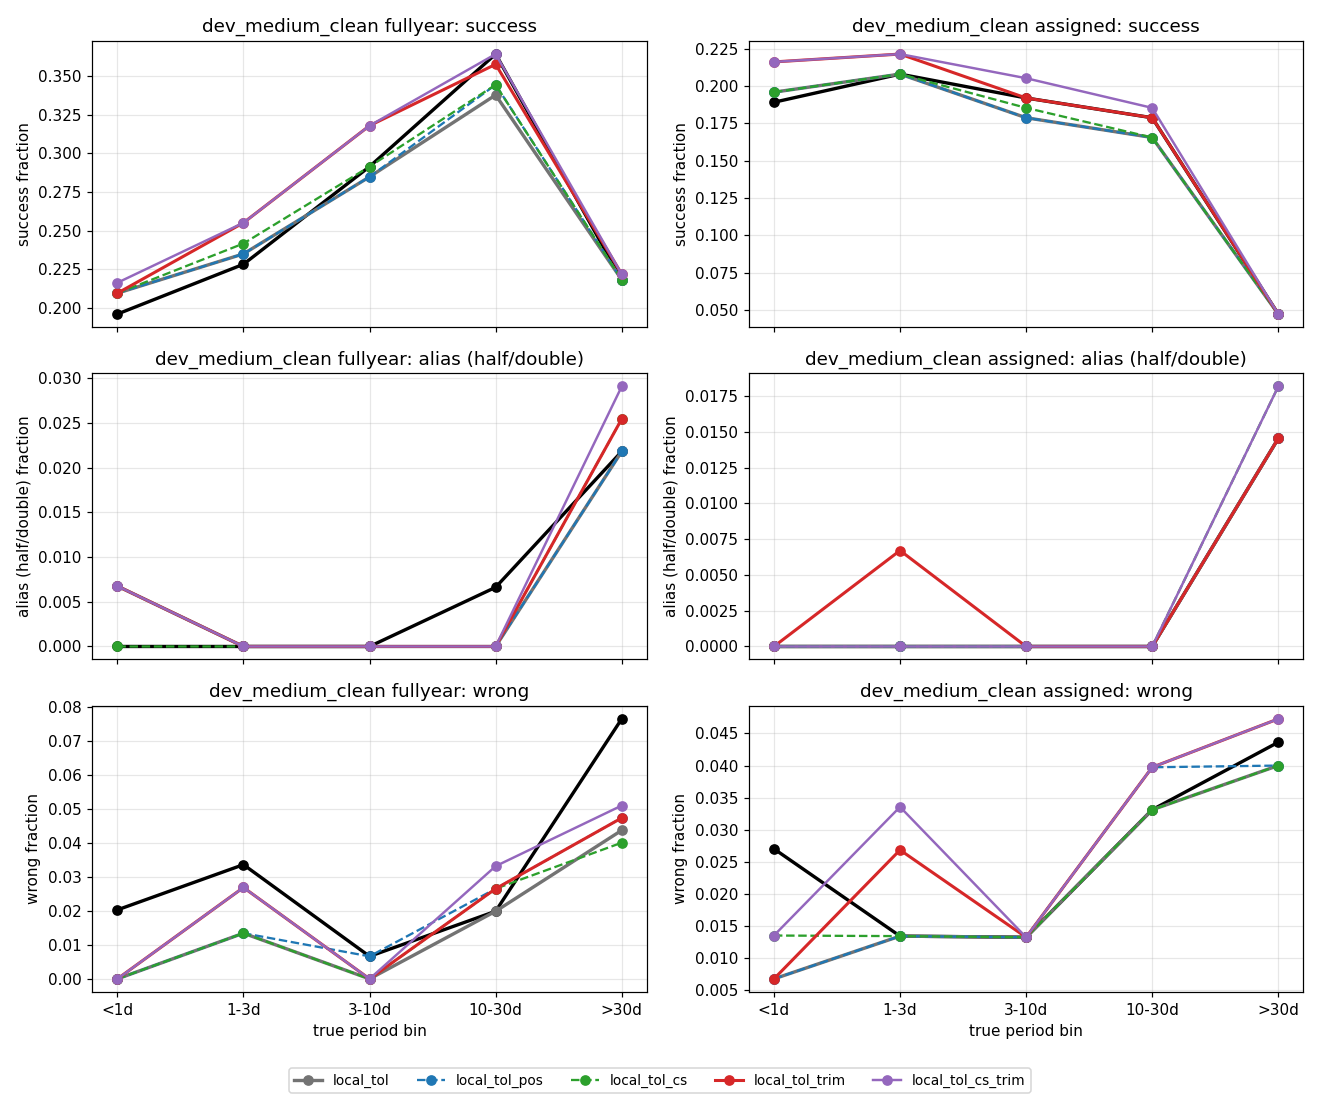

In [3]:
A.fig_bins(); display(Image(R / 'figures' / 'fig_bins.png'))

## Why local_tol loses _v7's stars
Left: failed gates of each lost star's closest success candidate. Middle: windows dropped by outlier rejection, lsq vs local_tol. Right: outcome of each lost star under each variant.

,mode,star_id,true_period,best_failed,best_n_dropped,lsq_n_dropped,best_snr,lsq_snr,best_fvt
0,fullyear,smarts-tess-v1.0-003313,0.6935,half_lag_consistency,1,1,2.401195,2.401193,1.000000
1,fullyear,smarts-tess-v1.0-008023,1.5320,frac_positive_heights,3,0,1.594046,4.762504,1.000000
2,fullyear,smarts-tess-v1.0-015438,2.8651,mean_height_snr,3,1,0.388381,2.031016,1.000000
3,fullyear,smarts-tess-v1.0-026704,4.8744,mean_height_snr,3,1,0.948669,1.040355,1.000000
4,fullyear,smarts-tess-v1.0-046873,8.5139,mean_height_snr,3,0,0.947994,1.541856,0.800000
5,fullyear,smarts-tess-v1.0-077778,14.0491,frac_vertex_tol,0,0,1.396302,1.497307,0.428571
6,fullyear,smarts-tess-v1.0-079146,14.2993,frac_vertex_tol,1,2,1.048621,1.017274,0.571429
7,fullyear,smarts-tess-v1.0-098694,17.8447,frac_vertex_tol,3,0,1.251029,1.617510,0.400000
8,fullyear,smarts-tess-v1.0-103059,18.6404,mean_height_snr,2,0,0.878193,1.338431,1.000000
9,fullyear,smarts-tess-v1.0-125098,22.5725,mean_height_snr,2,0,0.908999,1.174683,0.666667


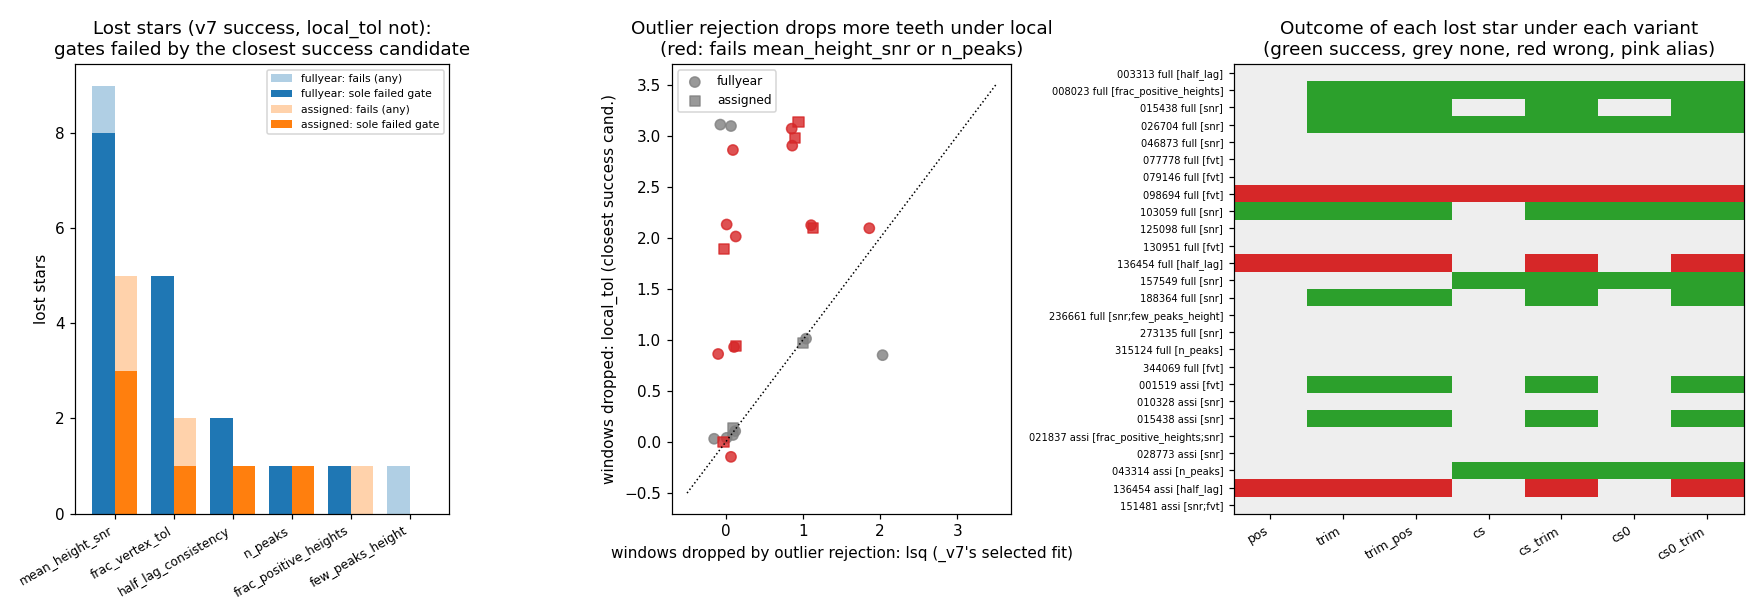

In [4]:
lost = pd.concat([pd.read_csv(R / 'data' / f'lost_{m}.csv').assign(mode=m) for m in ('fullyear', 'assigned')])
display(lost[['mode', 'star_id', 'true_period', 'best_failed', 'best_n_dropped', 'lsq_n_dropped', 'best_snr', 'lsq_snr', 'best_fvt']])
A.fig_lost_gates(); display(Image(R / 'figures' / 'fig_lost_gates.png'))

## frac_vertex_tol of candidates passing every other gate (threshold 0.6)

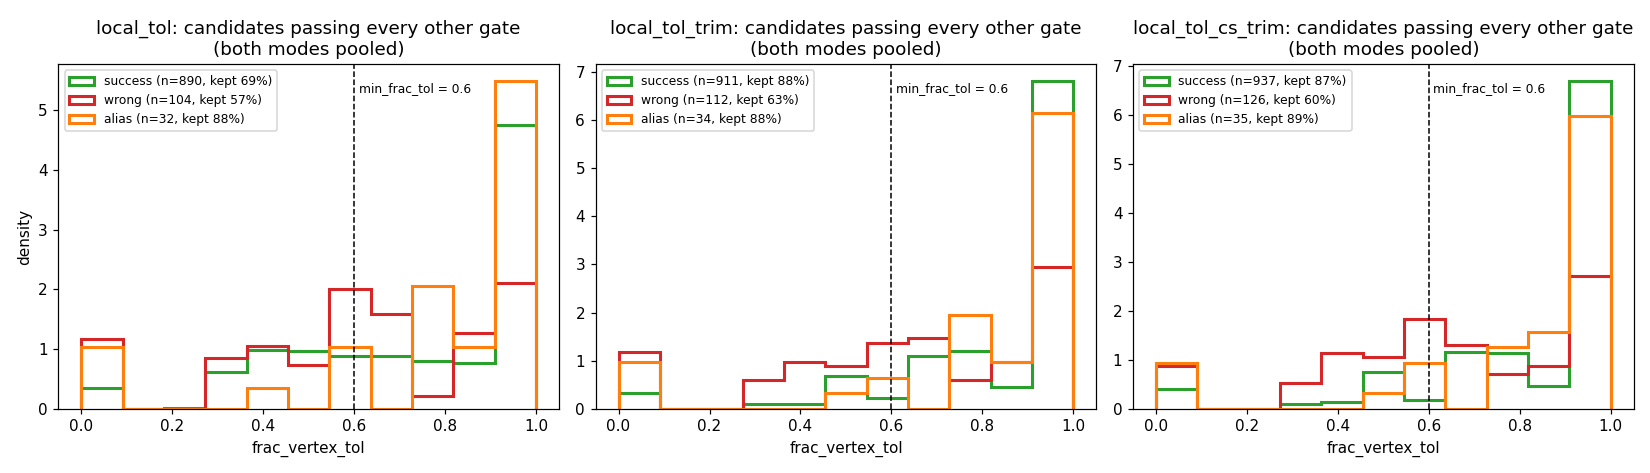

In [5]:
A.fig_fvt(); display(Image(R / 'figures' / 'fig_fvt.png'))

## Examples: recovered, still lost, newly wrong (local_tol vs local_tol_trim)
Computed by `examples.py` into `data/examples.pkl`.

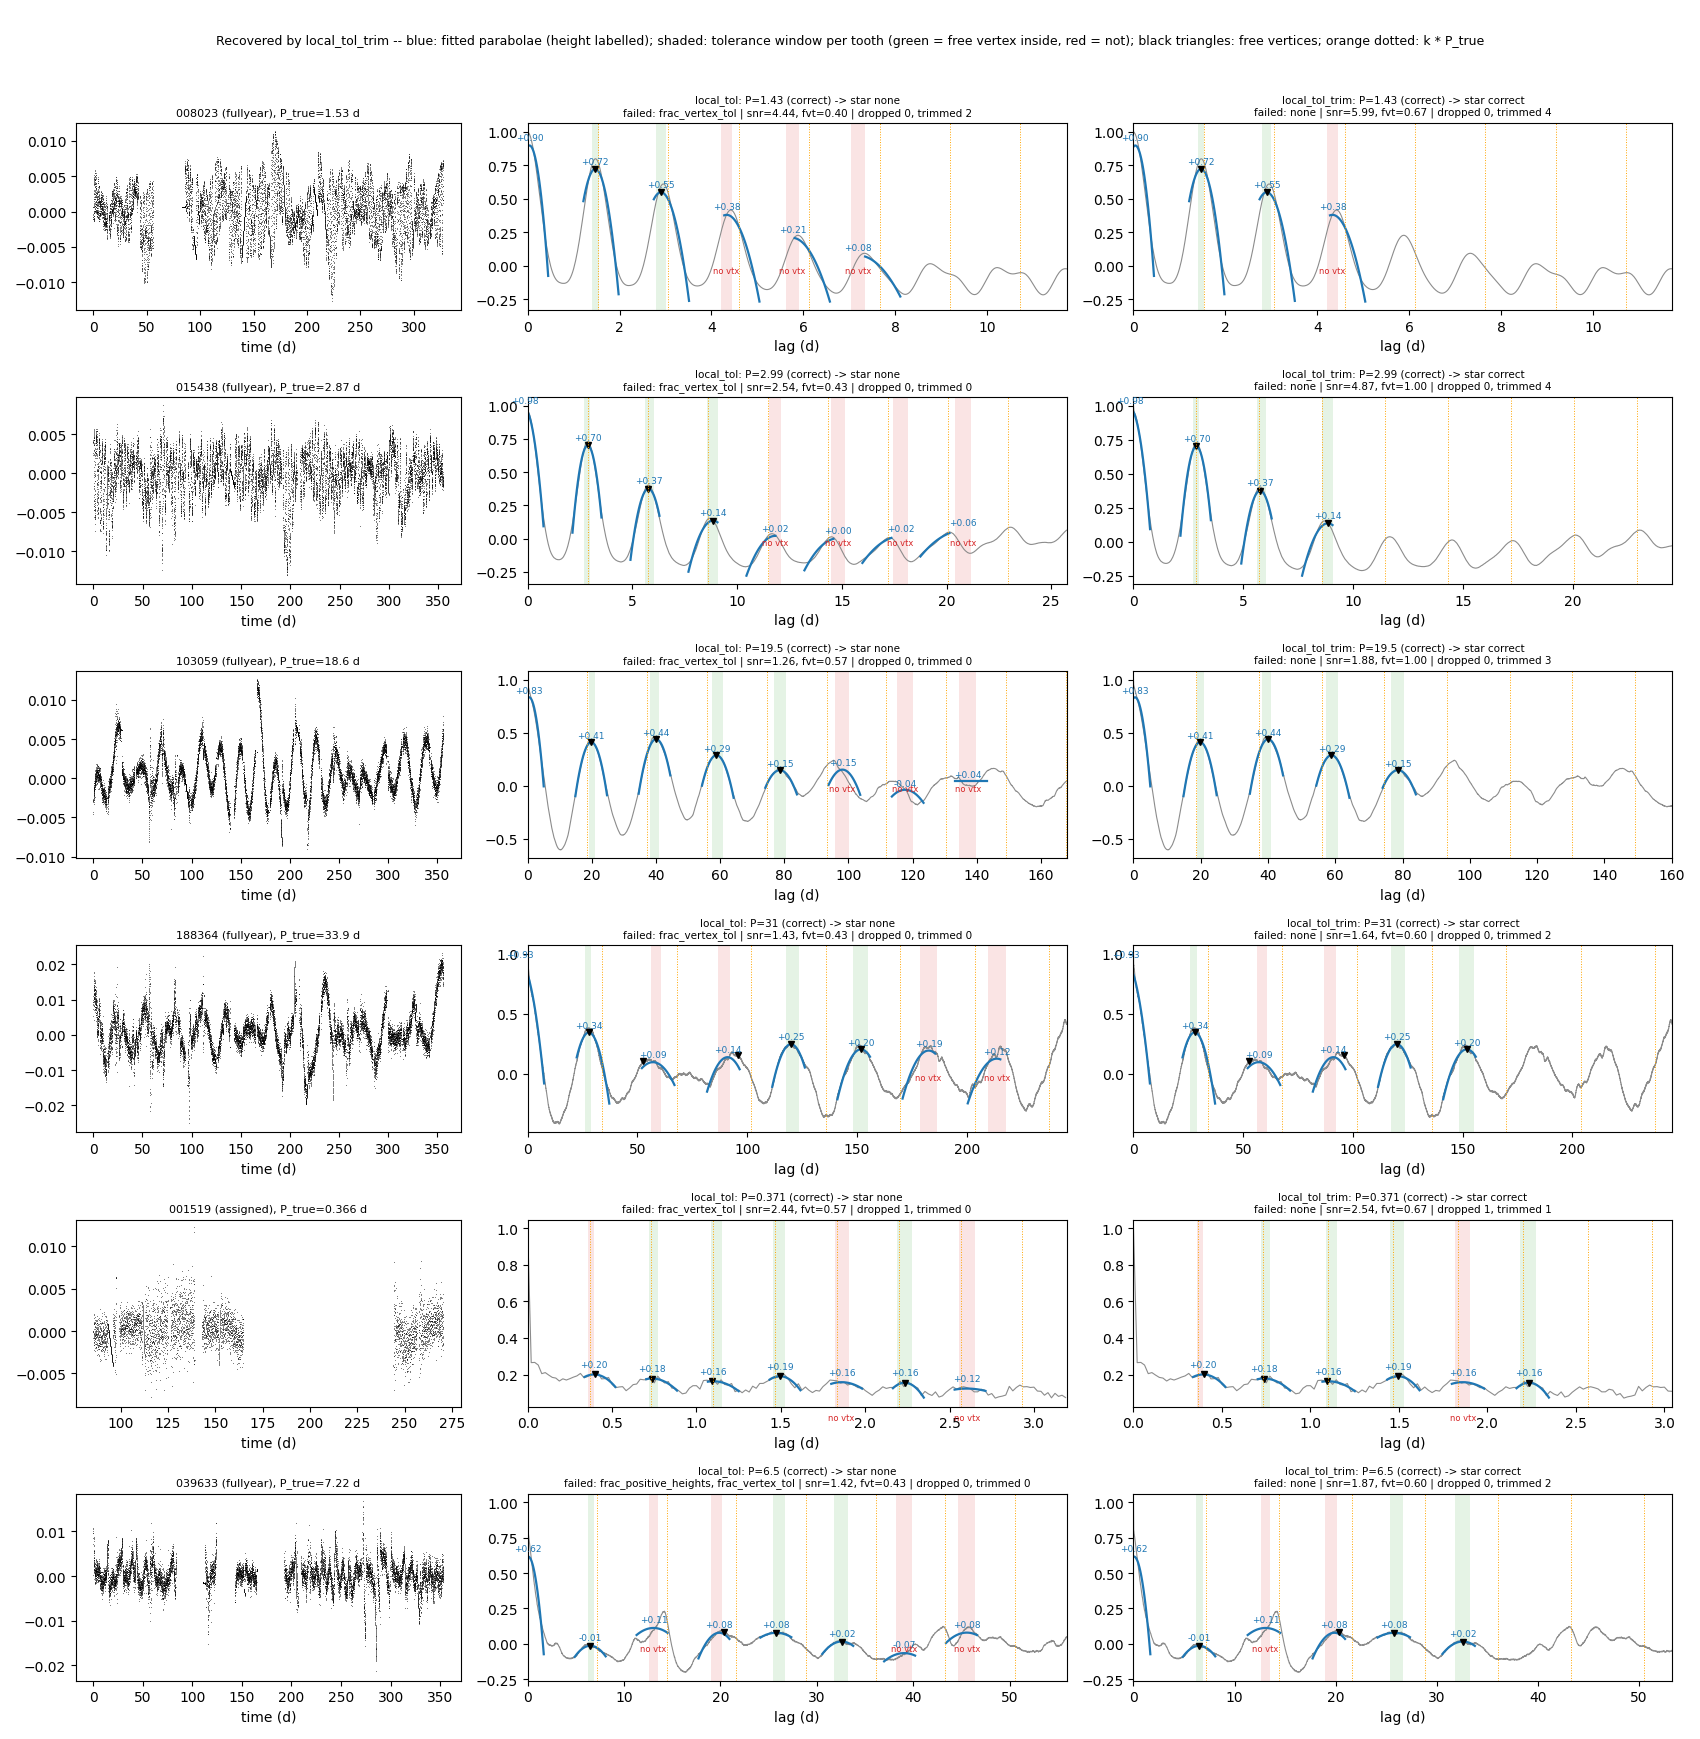

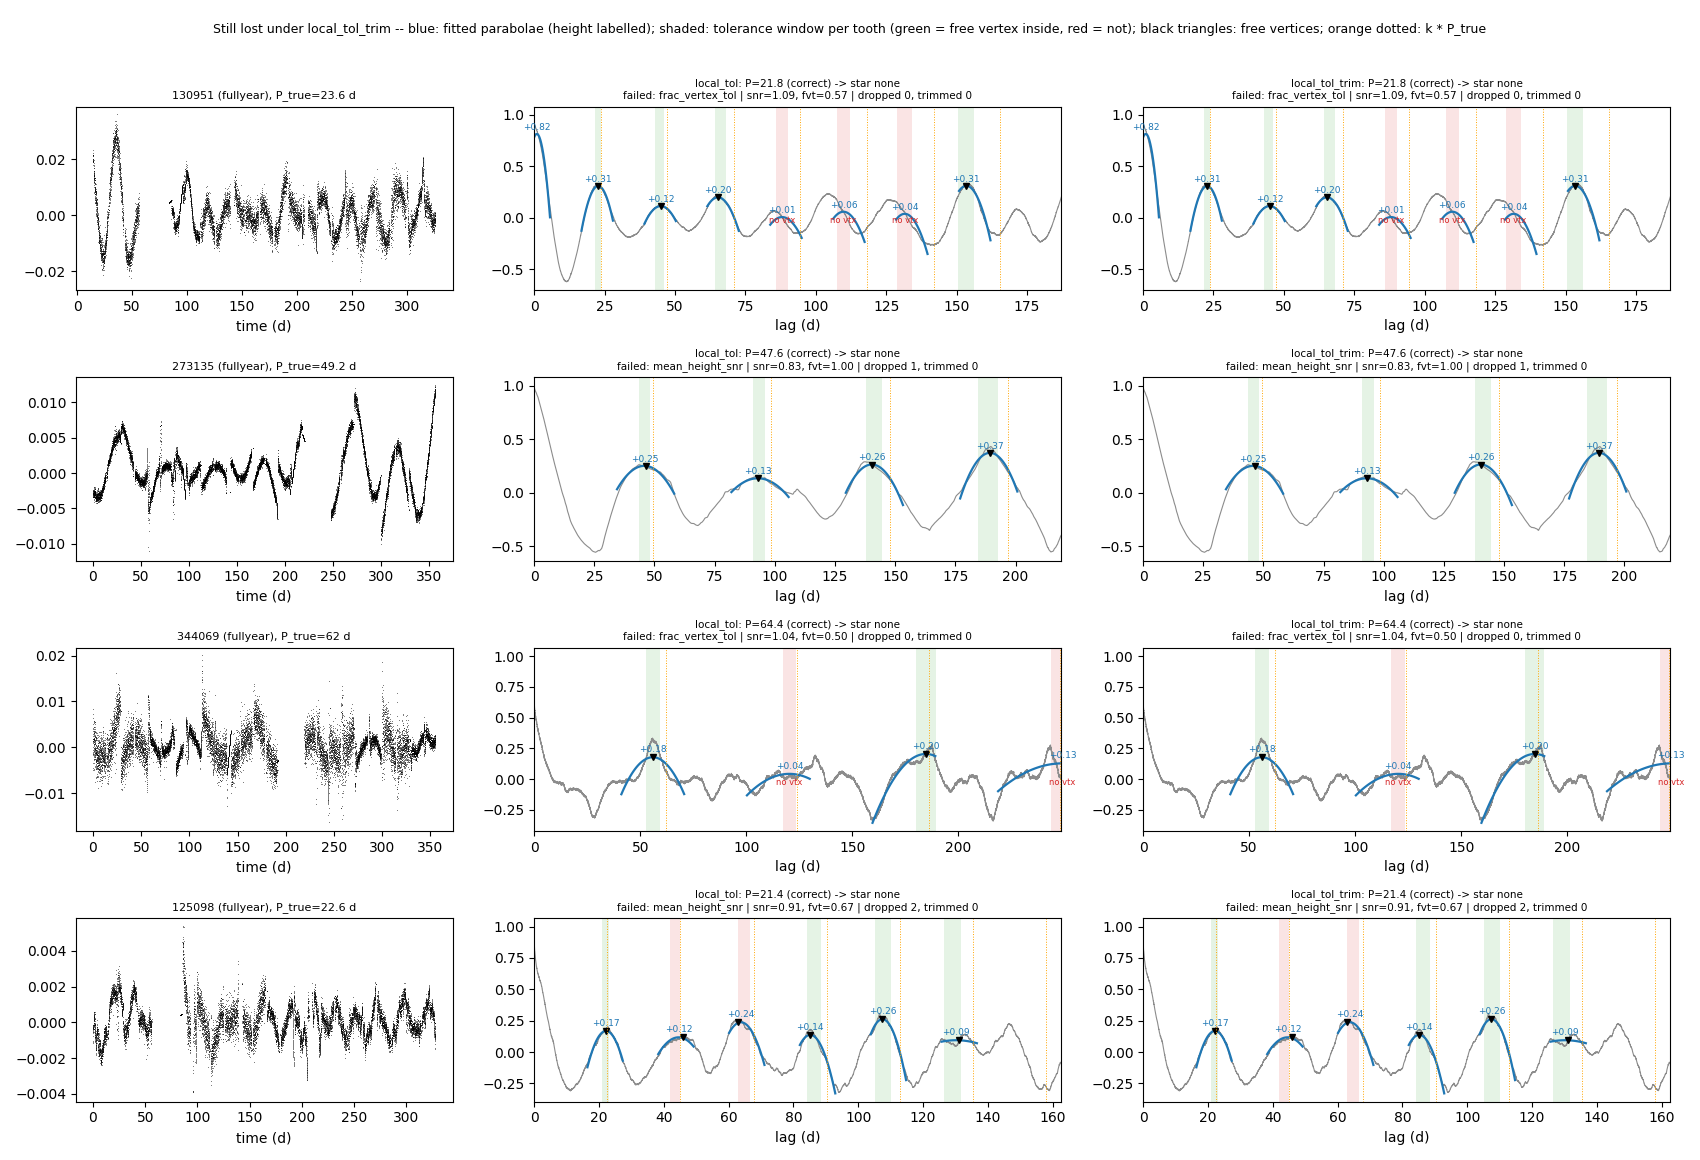

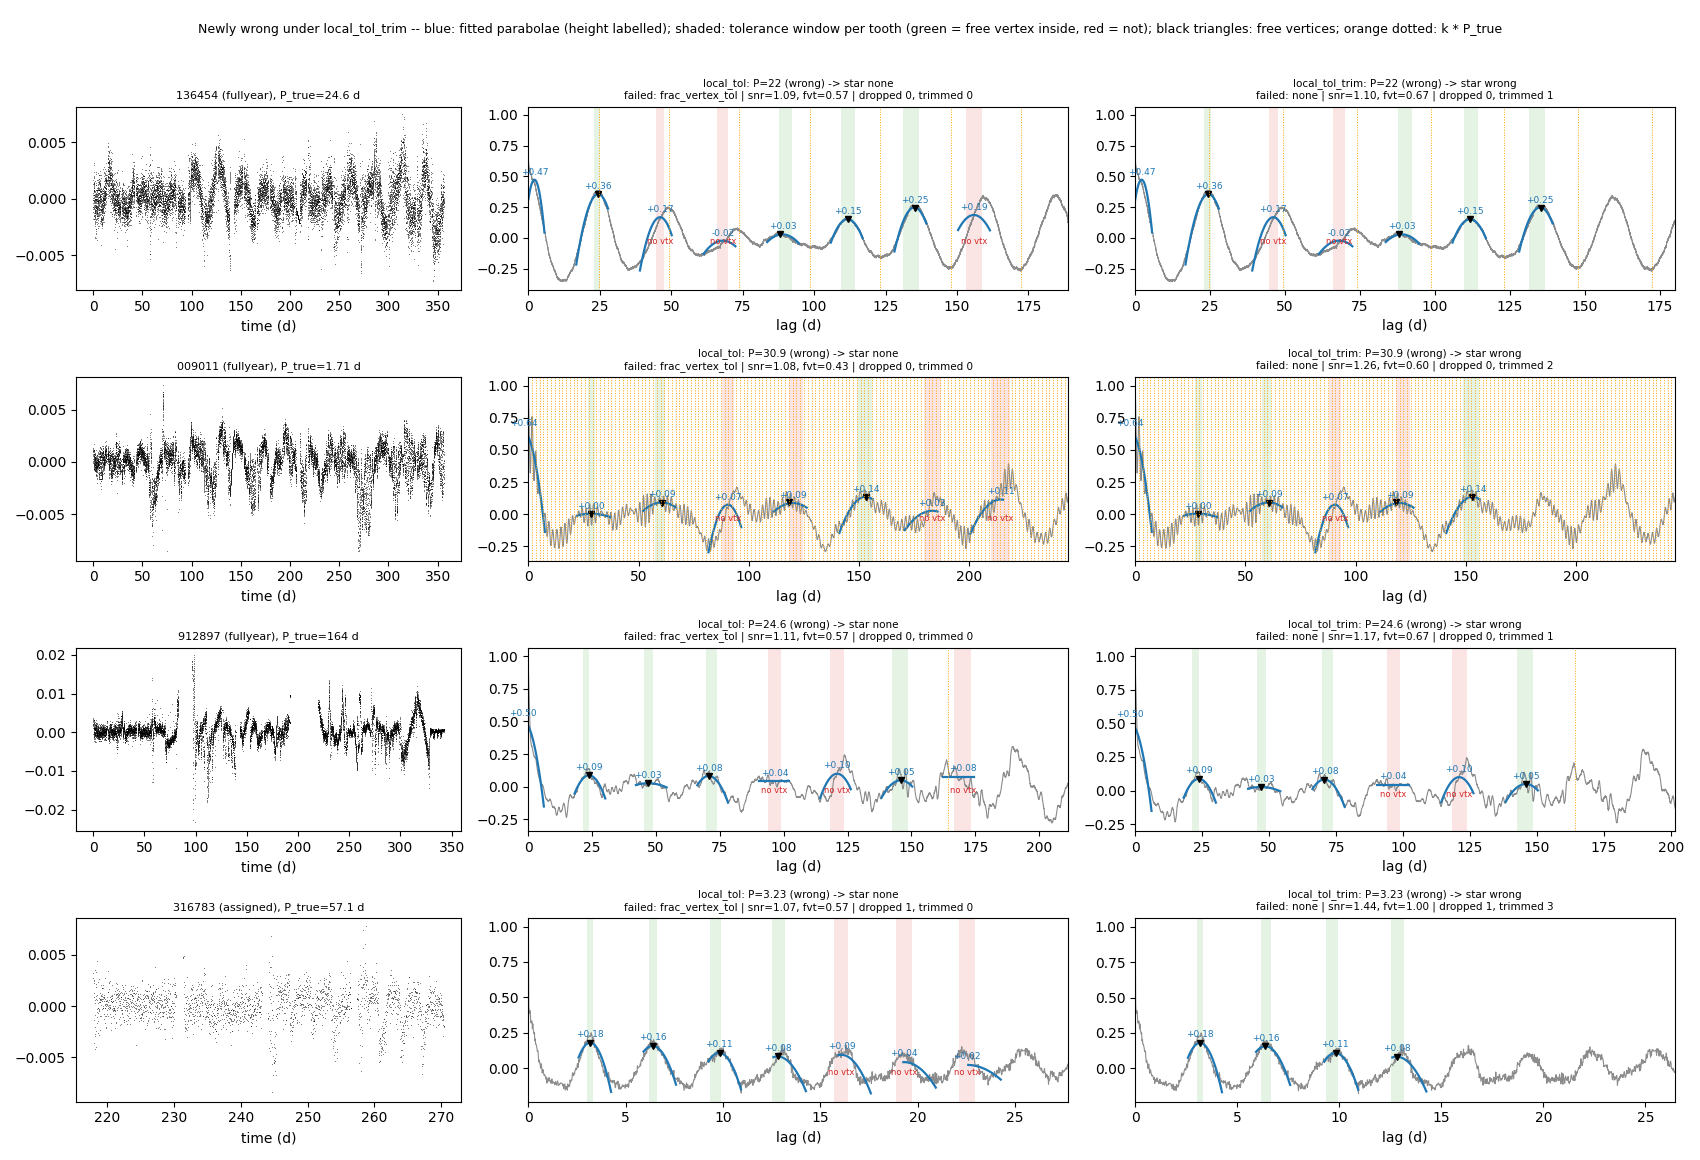

In [6]:
A.fig_examples()
for f in ('fig_examples_recovered.png', 'fig_examples_lost.png', 'fig_examples_newwrong.png'):
    display(Image(R / 'figures' / f))

## Runtime (profile_pipeline, 15 stars, full-year, 3 repeats)

,variant,mode,fit,total
0,local_tol_cs_trim,fullyear,0.135033,0.795653
1,local_tol,fullyear,0.101589,0.781369
2,local_tol_trim,fullyear,0.104949,0.785604


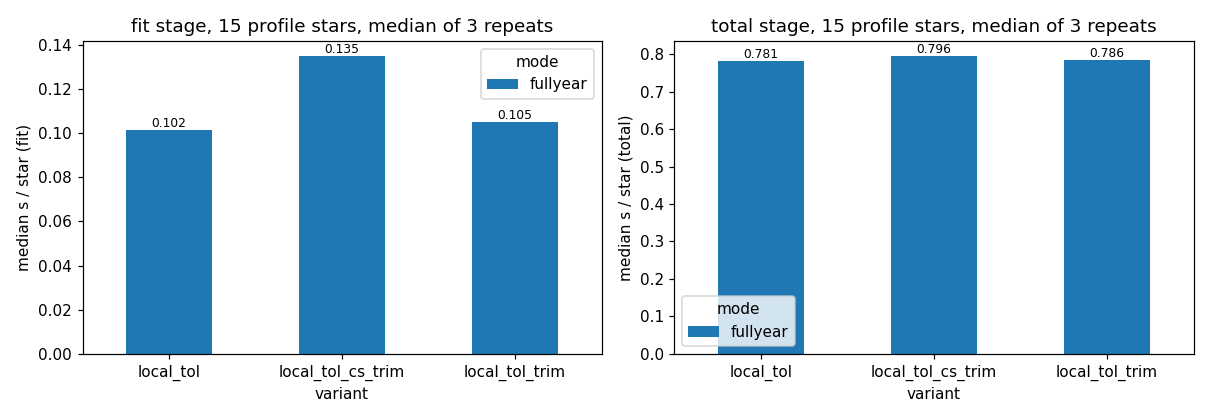

In [7]:
A.fig_runtime(); display(pd.read_csv(R / 'data' / 'runtime_summary.csv')); display(Image(R / 'figures' / 'fig_runtime.png'))

## Variant screen (all stars, both modes)

In [8]:
pd.read_csv(R / 'data' / 'screen_summary.csv').round(3)

,mode,variant,success,wrong,alias,none,precision,gained_vs_tol,lost_vs_tol,newwrong_vs_tol,lost_v7_recovered,lost_v7_total
0,fullyear,local_screen2,0.254,0.038,0.008,0.700,0.847,18,16,17,18,18
1,fullyear,local_tol,0.252,0.019,0.008,0.721,0.902,0,0,0,0,18
2,fullyear,local_tol_pos,0.253,0.023,0.008,0.716,0.891,1,0,3,1,18
3,fullyear,local_tol_trim,0.265,0.024,0.009,0.701,0.889,13,1,4,5,18
4,fullyear,local_tol_trim_pos,0.267,0.026,0.009,0.698,0.883,13,0,6,5,18
5,fullyear,local_tol_cs,0.255,0.019,0.008,0.717,0.903,3,0,1,3,18
6,fullyear,local_tol_cs_trim,0.268,0.026,0.010,0.696,0.880,15,1,6,6,18
7,fullyear,local_tol_cs0,0.253,0.021,0.007,0.720,0.902,4,3,2,4,18
8,fullyear,local_tol_cs0_trim,0.264,0.026,0.009,0.700,0.882,15,4,6,6,18
9,assigned,local_screen2,0.146,0.029,0.005,0.820,0.815,8,5,7,8,8
